# Expérimentations préliminaires — 3. LSTM (Keras)

Modèle temporel : au lieu de moyennes pré-calculées, le LSTM reçoit la **séquence** des
statistiques des 20 derniers matchs de chaque équipe (même saison, matchs strictement
antérieurs) et apprend lui-même à résumer la forme des équipes.

**Entrées.** Chaque pas de la séquence est un match passé de l'équipe, décrit par ses 525
statistiques. Prétraitement ajusté sur les équipes-matchs des saisons d'entraînement du pli
seulement : imputation (médiane) → standardisation (valeurs bornées à ±5 écarts-types) →
**ACP (critère de Kaiser, λ > 1)** → standardisation des composantes. On ajoute un indicateur
domicile/visiteur et un **indicateur de présence** (1 = vrai match) : les séquences plus
courtes que 20 (début de saison) sont rembourrées à gauche par des 0.

**Pourquoi l'ACP ?** Comme pour XGBoost, uniquement pour **alléger le modèle** : les 525
statistiques d'un match, très redondantes, sont remplacées par un nombre beaucoup plus petit
de composantes. La couche LSTM a alors beaucoup moins de poids (4 × 16 × (*p* + 16 + 1), où
*p* est le nombre de variables par pas), ce qui accélère l'entraînement et limite le
surapprentissage. Les composantes sont restandardisées (variance 1) pour que leurs échelles,
très différentes (λ₁ ≫ 1), ne déséquilibrent pas l'apprentissage. Un essai antérieur avec une
ACP conservant 95 % de la variance avait donné une log loss de validation moins bonne (plis 2
et 5 : 0,678 et 0,687 avec ACP contre 0,660 et 0,678 sans) ; le critère de Kaiser est retenu
ici par cohérence avec les autres modèles. La redondance restante est gérée par un
**dropout de 30 % sur les entrées** et un encodeur de petite taille.

**Architecture** (volontairement petite, peu de données) :

1. dropout sur les entrées, puis un encodeur `LSTM` **partagé** (16 unités) lit la séquence de l'équipe locale et celle de
   l'équipe visiteuse → $\mathbf h_L$, $\mathbf h_V$ ;
2. une tête dense reçoit $[\mathbf h_L, \mathbf h_V, \mathbf h_L - \mathbf h_V]$ →
   `Dense(32, relu)` → `Dropout(0.3)` → `Dense(1, sigmoid)`.

**Entraînement** : AdamW (lr = 10⁻³, weight decay = 10⁻⁴), lots de 128, arrêt précoce sur la
validation interne (patience 10 époques), puis réentraînement sur tout l'entraînement du pli
pour le nombre d'époques retenu. Keras 3 est utilisé avec le moteur (*backend*) PyTorch.

**Protocole commun** (voir `src/nhl_forecast/features/equipes.py` et
`src/nhl_forecast/evaluation/preliminaire.py`) :

- saisons régulières 2020-21 à 2025-26, statistiques d'**équipes** seulement, **toutes les
  colonnes** de `t_summary`, `t_percentages`, `t_summaryshooting`, `t_outshootoutshotby` et
  MoneyPuck (5 situations de jeu) ; seuls les identifiants, les colonnes vides ou constantes et
  les doublons exacts sont retirés, automatiquement ;
- validation croisée **chronologique** à 5 plis (fenêtre croissante) : le pli *k* entraîne sur
  les saisons 1 à *k* et teste sur la saison *k* + 1 ;
- hyperparamètres choisis sur les 20 % les plus récents des matchs d'entraînement du pli ;
- métriques : log loss, score de Brier, accuracy (seuil 0,5).

Avec `SAUVER = True`, les tableaux sont enregistrés en CSV (séparateur « ; ») dans
`reports/map6009/tables/` (préfixe `exp_`) et les prédictions dans
`data/processed/experimentation/` (lues par `04_comparaison.ipynb`).

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"  # avant l'import de keras

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

from nhl_forecast.evaluation.preliminaire import (
    FIG_DIR,
    GRAINE,
    ACPKaiser,
    exporter_tableau,
    formater,
    plis_chronologiques,
    predictions,
    resultats_par_pli,
    resume,
    sauver_predictions,
    separation_interne,
)
from nhl_forecast.features.equipes import (
    NOM_SAISON,
    charger_equipes,
    colonnes_stats,
    construire_matchs,
    indices_sequences,
)
from nhl_forecast.visualization.style import appliquer_style

SAUVER = True
LONGUEUR, CACHEE, DENSE, DROPOUT, DROPOUT_ENTREE = 20, 16, 32, 0.3, 0.3
LR, WEIGHT_DECAY, LOT, EPOQUES_MAX, PATIENCE = 1e-3, 1e-4, 128, 100, 10
appliquer_style()
print("Keras", keras.__version__, "– backend", keras.backend.backend())

Keras 3.15.1 – backend torch


In [2]:
eq = charger_equipes()
matchs = construire_matchs(eq)
STATS = colonnes_stats(eq)
idx = indices_sequences(eq, matchs, LONGUEUR)  # (n, 2, L) ; -1 = rembourrage
y = matchs["victoire_locale"].to_numpy().astype("float32")
plis = plis_chronologiques(matchs)
print(f"{len(matchs)} matchs, {len(STATS)} statistiques par match passé ; "
      f"part de pas réels : {(idx >= 0).mean():.1%}")

C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:182: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


7428 matchs, 525 statistiques par match passé ; part de pas réels : 86.5%


In [6]:
def preparer(pli):
    """Séquences (locale, visiteuse) ; prétraitement et ACP ajustés sur les saisons d'entraînement."""
    entr = eq["saison"].isin(pli["saisons_entr"]).to_numpy()
    pre = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(eq.loc[entr, STATS])
    z = np.clip(pre.transform(eq[STATS]), -5, 5)
    print(f"Pli {pli['pli']} – avant ACP : z {z.shape} (entraînement : {z[entr].shape})")
    acp = make_pipeline(ACPKaiser(random_state=GRAINE), StandardScaler()).fit(z[entr])
    z = acp.transform(z)
    print(f"Pli {pli['pli']} – après ACP : z {z.shape}")
    z = np.column_stack([z, 2 * eq["domicile"].to_numpy() - 1, np.ones(len(eq))])  # + présence
    z = np.vstack([z, np.zeros(z.shape[1])]).astype("float32")  # dernière ligne : rembourrage
    seq = z[np.where(idx >= 0, idx, len(z) - 1)]  # (n, 2, L, variables)
    print(f"Pli {pli['pli']} – séquences : {seq.shape}")
    return seq[:, 0], seq[:, 1], acp[0]


class Progression(keras.callbacks.Callback):
    """Barre de progression par époque, avec les pertes de la dernière époque."""

    def __init__(self, total, desc):
        super().__init__()
        self.total, self.desc = total, desc

    def on_train_begin(self, logs=None):
        self.barre = tqdm(total=self.total, desc=self.desc, unit="époque")

    def on_epoch_end(self, epoch, logs=None):
        self.barre.set_postfix({k: f"{v:.4f}" for k, v in (logs or {}).items()})
        self.barre.update()

    def on_train_end(self, logs=None):
        self.barre.total = self.barre.n  # arrêt précoce : la barre se termine à 100 %
        self.barre.refresh()
        self.barre.close()


def construire(n_var):
    keras.utils.set_random_seed(GRAINE)
    entree_l = keras.Input((LONGUEUR, n_var), name="local")
    entree_v = keras.Input((LONGUEUR, n_var), name="visiteur")
    dropout, encodeur = layers.Dropout(DROPOUT_ENTREE), layers.LSTM(CACHEE)  # partagés
    hl, hv = encodeur(dropout(entree_l)), encodeur(dropout(entree_v))
    x = layers.Concatenate()([hl, hv, layers.Subtract()([hl, hv])])
    x = layers.Dropout(DROPOUT)(layers.Dense(DENSE, activation="relu")(x))
    sortie = layers.Dense(1, activation="sigmoid")(x)
    modele = keras.Model([entree_l, entree_v], sortie)
    modele.compile(optimizer=keras.optimizers.AdamW(LR, weight_decay=WEIGHT_DECAY),
                   loss="binary_crossentropy")
    return modele

## 1. Entraînement par pli

In [9]:
preds, choix, acp, courbes = [], [], [], {}
for pli in plis:
    Xl, Xv, kaiser = preparer(pli)
#     print(f"Pli {pli['pli']} – Xl : {Xl.shape}")
#     print(f"Pli {pli['pli']} – Xv : {Xv.shape}")
    ajust, val = separation_interne(pli["entr"])
    # (a) arrêt précoce sur la validation interne
    m = construire(Xl.shape[-1])
    h = m.fit([Xl[ajust], Xv[ajust]], y[ajust], validation_data=([Xl[val], Xv[val]], y[val]),
              epochs=EPOQUES_MAX, batch_size=LOT, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
                         Progression(EPOQUES_MAX, f"Pli {pli['pli']} – arrêt précoce")])
    courbes[pli["pli"]] = pd.DataFrame(h.history)
    n_epoques = int(np.argmin(h.history["val_loss"]) + 1)
    # (b) réentraînement sur tout l'entraînement du pli, n_epoques époques
    m = construire(Xl.shape[-1])
    e = pli["entr"]
    m.fit([Xl[e], Xv[e]], y[e], epochs=n_epoques, batch_size=LOT, verbose=0,
          callbacks=[Progression(n_epoques, f"Pli {pli['pli']} – réentraînement")])
    p = m.predict([Xl[pli["test"]], Xv[pli["test"]]], verbose=0).ravel()
    preds.append(predictions(matchs, pli, p, "LSTM"))
    saison = NOM_SAISON[pli["saison_test"]]
    choix.append({"Pli": pli["pli"], "Saison testée": saison,
                  "Époques retenues": n_epoques,
                  "Log loss (validation)": min(h.history["val_loss"])})
    acp.append({"Pli": pli["pli"], "Saison testée": saison,
                "Composantes ACP": kaiser.n_components_,
                "Variance expliquée (%)": round(100 * kaiser.variance_expliquee_, 1),
                "Paramètres du modèle": m.count_params()})
preds = pd.concat(preds, ignore_index=True)
tab_choix = pd.DataFrame(choix)
tab_acp = pd.DataFrame(acp)
formater(tab_choix)

Pli 1 – avant ACP : z (14856, 525) (entraînement : (1736, 525))
Pli 1 – après ACP : z (14856, 89)
Pli 1 – séquences : (7428, 2, 20, 91)


Pli 1 – réentraînement: 100%|██████████| 20/20 [00:04<00:00,  4.81époque/s, loss=0.6184]


Pli 2 – avant ACP : z (14856, 525) (entraînement : (4360, 525))
Pli 2 – après ACP : z (14856, 89)
Pli 2 – séquences : (7428, 2, 20, 91)


Pli 2 – réentraînement: 100%|██████████| 11/11 [00:05<00:00,  2.03époque/s, loss=0.6700]


Pli 3 – avant ACP : z (14856, 525) (entraînement : (6984, 525))
Pli 3 – après ACP : z (14856, 89)
Pli 3 – séquences : (7428, 2, 20, 91)


Pli 3 – réentraînement: 100%|██████████| 12/12 [00:14<00:00,  1.18s/époque, loss=0.6380]


Pli 4 – avant ACP : z (14856, 525) (entraînement : (9608, 525))
Pli 4 – après ACP : z (14856, 89)
Pli 4 – séquences : (7428, 2, 20, 91)


Pli 4 – réentraînement: 100%|██████████| 13/13 [00:15<00:00,  1.18s/époque, loss=0.6356]


Pli 5 – avant ACP : z (14856, 525) (entraînement : (12232, 525))
Pli 5 – après ACP : z (14856, 89)
Pli 5 – séquences : (7428, 2, 20, 91)


Pli 5 – réentraînement: 100%|██████████| 10/10 [00:14<00:00,  1.47s/époque, loss=0.6532]


Pli,Saison testée,Époques retenues,Log loss (validation)
1,2021-22,20,0.6749
2,2022-23,11,0.6883
3,2023-24,12,0.6771
4,2024-25,13,0.6680
5,2025-26,10,0.6854


In [10]:
formater(tab_acp)

Pli,Saison testée,Composantes ACP,Variance expliquée (%),Paramètres du modèle
1,2021-22,89,89.0000,8513
2,2022-23,89,88.2000,8513
3,2023-24,89,88.1000,8513
4,2024-25,89,88.0000,8513
5,2025-26,89,88.0000,8513


## 2. Résultats par pli

In [11]:
tab_plis = resultats_par_pli(preds)
if SAUVER:
    exporter_tableau(tab_plis, "exp_lstm_par_pli")
    exporter_tableau(tab_choix, "exp_lstm_hyperparametres")
    exporter_tableau(tab_acp, "exp_lstm_composantes")
    sauver_predictions(preds, "03_lstm")
formater(tab_plis)

Modèle,Pli,Saison testée,n,Log loss,Brier,Accuracy
LSTM,1,2021-22,1312,0.6928,0.2496,0.5549
LSTM,2,2022-23,1312,0.6864,0.2465,0.5633
LSTM,3,2023-24,1312,0.6900,0.2479,0.5633
LSTM,4,2024-25,1312,0.6837,0.2452,0.5450
LSTM,5,2025-26,1312,0.6873,0.2468,0.5511


## 3. Résumé (moyenne ± écart-type sur les 5 plis)

In [12]:
tab_resume = resume(preds)
if SAUVER:
    exporter_tableau(tab_resume, "exp_lstm_resume")
formater(tab_resume)

Modèle,Log loss,Brier,Accuracy
LSTM,0.6880 ± 0.0035,0.2472 ± 0.0017,0.5555 ± 0.0079


## 4. Courbe d'apprentissage (dernier pli)

Log loss sur l'ajustement (*training*, avec dropout) et sur la validation interne à chaque
époque. L'écart qui se creuse après quelques époques illustre le surapprentissage rapide sur
un petit jeu de données bruité.

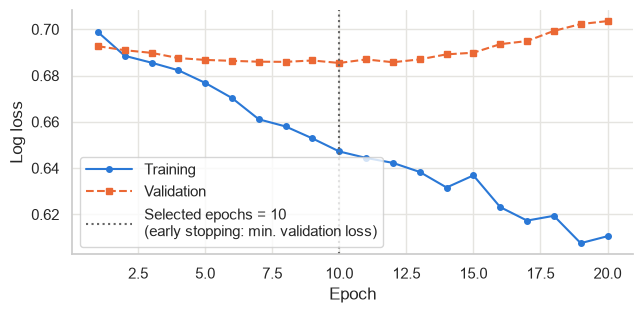

In [15]:
c = courbes[plis[-1]["pli"]]
ep = np.arange(1, len(c) + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ep, c["loss"], linestyle="-", marker="o", label="Training")
ax.plot(ep, c["val_loss"], linestyle="--", marker="s", label="Validation")
n_sel = tab_choix["Époques retenues"].iloc[-1]
ax.axvline(n_sel, color="0.4", linestyle=":", marker="",
           label=f"Selected epochs = {n_sel}\n(early stopping: min. validation loss)")
ax.set(xlabel="Epoch", ylabel="Log loss")
ax.legend()
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_lstm_apprentissage.png", dpi=300, bbox_inches="tight")
plt.show()